# 🧪 LAB: Classifying IoT Device Types with Machine Learning

**Motivation**: The rapid expansion of the Internet of Things (IoT) has dramatically increased the number and diversity of devices connected to modern networks. While these devices bring convenience and functionality, they also introduce new security vulnerabilities. In particular, the presence of unauthorized or malicious IoT devices within a network can pose a serious threat to organizational infrastructure.

To mitigate this risk, it is critical to develop tools that can automatically identify the type of IoT devices connected to a network based on their network traffic behavior. In this lab, you will explore this challenge by building and comparing machine learning models that classify IoT devices by type using real-world network data.

To this end, in this lab you will be evaluating the effectiveness of different ensemble methods and reflecting on their performance. You will also compare these methods with neural network models.

**Dataset Description**: To do this lab, you will be working with a dataset that contains network traffic features collected from various Internet of Things (IoT) devices operating in a simulated smart home environment. The goal is to automatically identify the type of IoT device connected to the network based on its traffic behavior.

Problem Type: Multi-class classification — identifying which device type (e.g., camera, thermostat) corresponds to a given network traffic sample.

- Instances: 1,800 network traffic captures.

- Features: ~297 attributes per instance, including packet-level and flow-level statistics, protocol usage patterns, temporal and size-based features, categorical indicators (e.g., protocol types)

- Target Variable: device_category — class label indicating the type of IoT device (e.g., 'Light', 'Camera', 'Thermostat', etc.)

---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

---
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


NAME(s) = "Michelle J., Max G., Kavan W."

## Part 1: Data Preparation and Visualization (15 points) - Michelle

In this part, you will prepare the data for modeling and explore it using dimensionality reduction techniques.

You should do the following:

1. **Load the data**  
   Load `iot_devices_train.csv` as the training dataset and `iot_devices_reporting.csv` as the reporting dataset.

2. **Separate inputs and outcomes**  
   - The outcome variable corresponds to the `"device_category"` column.  
   - Separate this column from the input features.

3. **Encode the outcome variable**  
   - The outcome variable (type of device) is currently a text variable.  
   - Convert it into numeric values so that each device type is assigned a unique number. Make sure device types are encoded correctly and consistently across the training and reporting sets.
   - *Hint:* You can use `LabelEncoder` from `scikit-learn` for this task.

4. **Dimensionality reduction for visualization**  
   - Apply both PCA and UMAP to reduce the dimensionality of the training set to two dimensions.  
   - Before applying PCA or UMAP, standardize the features. **IMPORTANT:** This standardization is only for the dimensionality reduction visualizations.  
   - Use **pipelines** to apply standardization followed by each dimensionality reduction method.

5. **Visualize the results**  
   - Create two scatter plots (one for PCA, one for UMAP) showing the 2D representations.  
   - Color each point according to its IoT device label.

6. **Compare the methods**  
   - Briefly discuss the differences between the PCA and UMAP visualizations.  
   - What patterns or separations can you observe? Which method seems to give better information about the structure in the data?


In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline

# Try importing UMAP, install if not available
try:
    import umap
except ImportError:
    !pip install umap-learn -q
    import umap

# 1. Load the data
train_df = pd.read_csv('iot_devices_train.csv')
report_df = pd.read_csv('iot_devices_reporting.csv')

print(f"Train set shape: {train_df.shape}")
print(f"Reporting set shape: {report_df.shape}")

# 2. Separate inputs and outcomes
X_train = train_df.drop(columns=['device_category'])
y_train = train_df['device_category']

X_report = report_df.drop(columns=['device_category'])
y_report = report_df['device_category']

# 3. Encode the outcome variable
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_report_encoded = label_encoder.transform(y_report)

# Print mapping
class_mapping = {index: label for index, label in enumerate(label_encoder.classes_)}
print("Encoded Classes Mapping:")
for k, v in class_mapping.items():
    print(f"  {k}: {v}")

Train set shape: (900, 298)
Reporting set shape: (900, 298)
Encoded Classes Mapping:
  0: TV
  1: baby_monitor
  2: lights
  3: motion_sensor
  4: security_camera
  5: smoke_detector
  6: socket
  7: thermostat
  8: watch


In [28]:
# 4. Define and fit standardizing Pipelines for PCA and UMAP
pca_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=2, random_state=42))
])

umap_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('umap', umap.UMAP(n_components=2, random_state=42))
])

# Fit and transform the training features
X_train_pca = pca_pipeline.fit_transform(X_train)
X_train_umap = umap_pipeline.fit_transform(X_train)
print("PCA and UMAP projections completed!")

/Users/maxguryan/Desktop/DS/DS4021/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


PCA and UMAP projections completed!


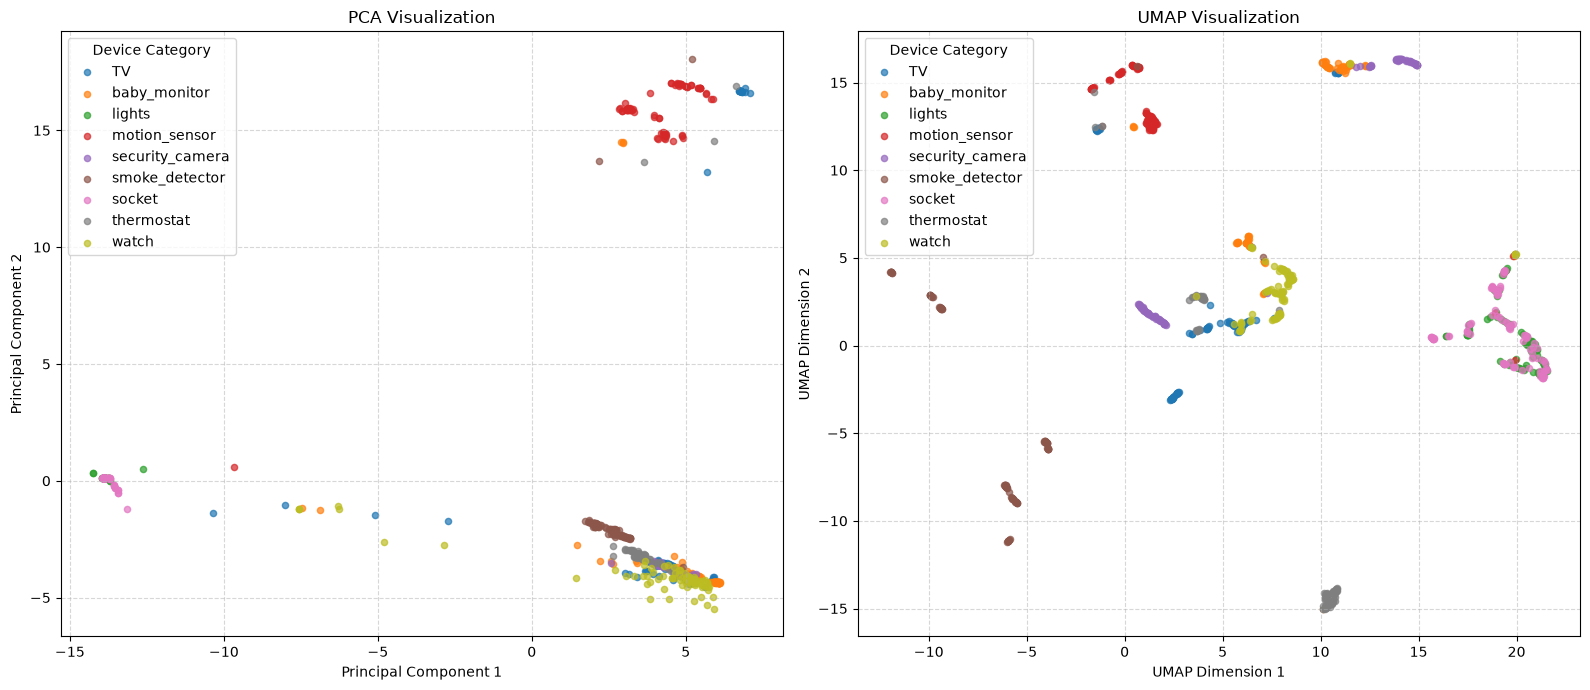

In [29]:
# 5. Visualize 2D projections side-by-side colored by device category
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Plot PCA projection
for class_idx, class_name in class_mapping.items():
    mask = (y_train_encoded == class_idx)
    axes[0].scatter(X_train_pca[mask, 0], X_train_pca[mask, 1], label=class_name, alpha=0.7, s=20)
axes[0].set_title('PCA Visualization')
axes[0].set_xlabel('Principal Component 1')
axes[0].set_ylabel('Principal Component 2')
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(title='Device Category')

# Plot UMAP projection
for class_idx, class_name in class_mapping.items():
    mask = (y_train_encoded == class_idx)
    axes[1].scatter(X_train_umap[mask, 0], X_train_umap[mask, 1], label=class_name, alpha=0.7, s=20)
axes[1].set_title('UMAP Visualization')
axes[1].set_xlabel('UMAP Dimension 1')
axes[1].set_ylabel('UMAP Dimension 2')
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(title='Device Category')

plt.tight_layout()
plt.show()

## Part 2: Ensemble Methods with Scikit-Learn (40 points) - Max

In this part, you will compare the performance of **Gradient Boosting** and **Random Forests** on the IoT device classification dataset.

Your tasks are:

1. **Pre-analysis Discussion and reflection**  
  Before starting, think about whether the typical preprocessing steps in machine learning (e.g., scaling, normalization, encoding) are necessary for tree-based ensemble methods such as Random Forests and Gradient Boosting. Write a brief explanation of which preprocessing steps (if any) you believe are required for these methods and why, and apply them only if you consider them necessary.


2. **Optimize each model**  
   Train and optimize both models using different combinations of the following hyperparameters:

   - Gradient Boosting: `max_depth`, `learning_rate`  
   - Random Forest: `max_depth`, `max_features`  

   *Tip:* Check the documentation of each model to understand what values make sense for these parameters.

   To ensure a fair comparison:
   - Use the same cross-validation object when optimizing both models.  
   - Use the same candidate values for `max_depth` across models.  
   - To keep the runtime manageable, test only THREE different values for each hyperparameter.  
   - Use a 5-fold cross-validation for tuning.

3. **Evaluate performance**  
   - Use each optimized model to evaluate performance on the reporting data.  
   - Report the accuracy and confusion matrix.
   - Report the total fitting time for the hyperparameter search. To measure it, record the time right before fitting the method and again immediately after it finishes. You can record the time using the `time()` function from the Python package `time`. Then, calculate the difference between the two to obtain the total training time (in minutes).
   - Discuss which types of devices are predicted most accurately and which are more difficult to classify.

4. **Analyze feature importance**  
   - Compare the feature importance resulting from each model. Do this both qualitatively and quantitatively (for example, by examining the similarity between feature importance vectors).
   - Are the most important features consistent across models? Which ones are these? Please, keep this discussion concise but thoughtful—focus on patterns and possible explanations rather than just listing numbers.
    
5. **Reflection**:  How do you think the models performed compared to random guessing?  *Hint:* A baseline accuracy of 50% assumes uniform random guessing between two categories. Since this is a multi-class problem, how should that baseline change?

**ANSWERS**

1. Feature scaling and normalization are not necessary for Random Forests and Gradient Boosting. NaN values are not handled natively by either model type, and will need to be dealt with during the pre-analysis stage. One hot encoding is neceessary, if categorical features are present, for both model types because they require numerical rather than categorical inputs.

In [30]:
# check for categorical features and NaN values

print(X_train.select_dtypes(exclude="number").shape[1], "non-numeric columns")
print(X_train.isna().sum().sum(), "missing values")

0 non-numeric columns
0 missing values


In [31]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from time import time

rs = 42
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=rs)
gb = GradientBoostingClassifier(random_state=rs)
rf = RandomForestClassifier(random_state=rs)

depths = [5,8,12]

gb_param_grid = {
    'max_depth' : depths,
    'learning_rate' : [0.05, 0.15, 0.3]
}

rf_param_grid = {
    'max_depth' : depths,
    'max_features' : ['sqrt', 'log2', 0.3]
}

In [32]:
# Random Forest Search
rf_search = GridSearchCV(
    estimator=rf,
    param_grid=rf_param_grid,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

start = time()
rf_search.fit(X_train, y_train_encoded)
rf_time = (time() - start)/60

# Random Forest Outputs
print(f"RF best params: {rf_search.best_params_}")
print(f"RF best CV accuracy: {rf_search.best_score_:.4f}")
print(f"RF search time: {rf_time:.2f} minutes")

RF best params: {'max_depth': 12, 'max_features': 'log2'}
RF best CV accuracy: 0.8878
RF search time: 0.03 minutes


In [33]:
# Gradient Boosting Search

gb_search = GridSearchCV(
    estimator=gb,
    param_grid=gb_param_grid,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

start = time()
gb_search.fit(X_train, y_train_encoded)
gb_time = (time() - start)/60

# Gradient Boosting Outputs
print(f"GB best params: {gb_search.best_params_}")
print(f"GB best CV accuracy: {gb_search.best_score_:.4f}")
print(f"GB search time: {gb_time:.2f} minutes")


GB best params: {'learning_rate': 0.15, 'max_depth': 5}
GB best CV accuracy: 0.8800
GB search time: 0.87 minutes


In [34]:
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

gb_best = gb_search.best_estimator_
rf_best = rf_search.best_estimator_

gb_pred = gb_best.predict(X_report)
rf_pred = rf_best.predict(X_report)

gb_acc = accuracy_score(y_report_encoded, gb_pred)
rf_acc = accuracy_score(y_report_encoded, rf_pred)

results = pd.DataFrame({
    'Model': ['Gradient Boosting', 'Random Forest'],
    'Best params': [gb_search.best_params_, rf_search.best_params_],
    'CV accuracy': [gb_search.best_score_, rf_search.best_score_],
    'Reporting accuracy': [gb_acc, rf_acc],
    'Search time (min)': [gb_time, rf_time]
})
results

,Model,Best params,CV accuracy,Reporting accuracy,Search time (min)
0,Gradient Boosting,"{'learning_rate': 0.15, 'max_depth': 5}",0.880000,0.611111,0.867784
1,Random Forest,"{'max_depth': 12, 'max_features': 'log2'}",0.887778,0.671111,0.028892


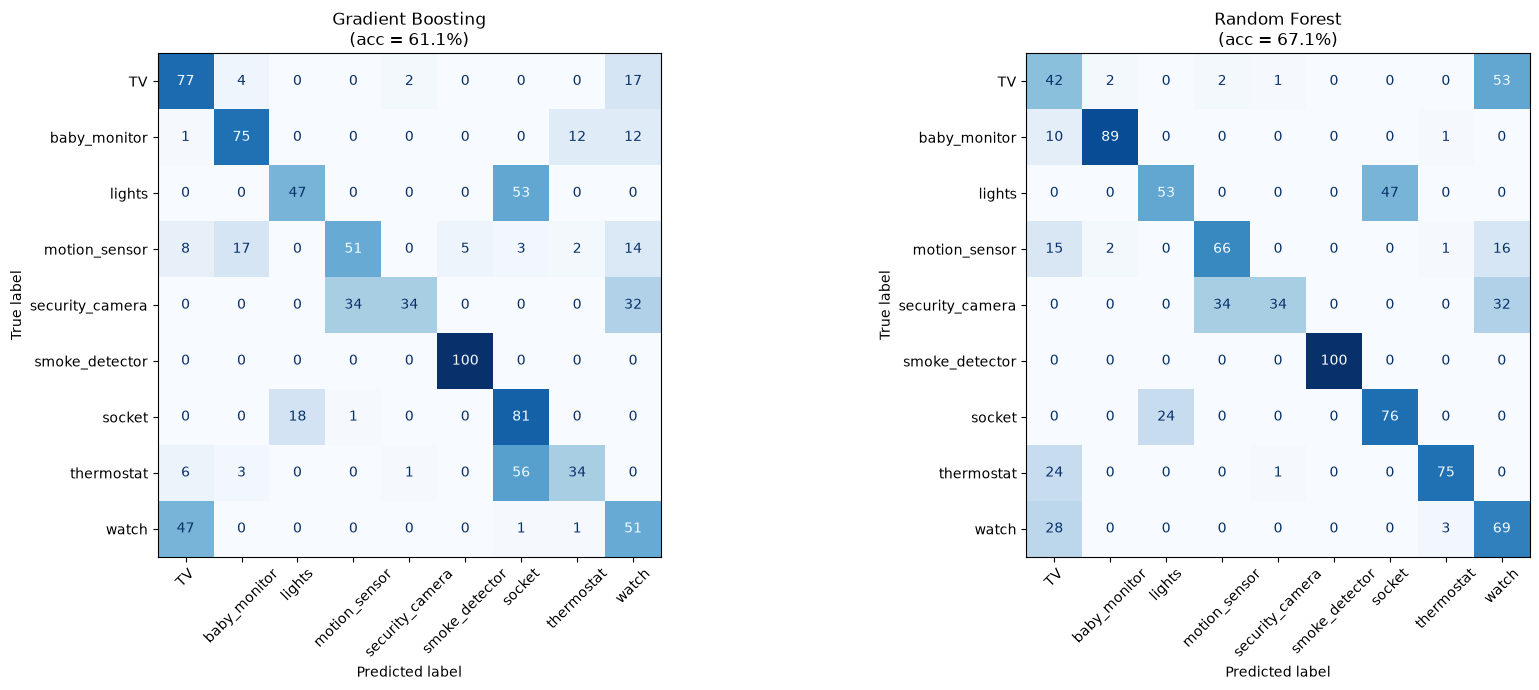

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, name, pred, acc in zip(axes,
                               ['Gradient Boosting', 'Random Forest'],
                               [gb_pred, rf_pred],
                               [gb_acc, rf_acc]):
    cm = confusion_matrix(y_report_encoded, pred)
    ConfusionMatrixDisplay(cm, display_labels=label_encoder.classes_).plot(
        ax=ax, cmap='Blues', colorbar=False, xticks_rotation=45)
    ax.set_title(f"{name}\n(acc = {acc*100:.1f}%)")

plt.tight_layout()
plt.show()


In [36]:
def per_class_acc(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    return cm.diagonal() / cm.sum(axis=1)   # recall per class

per_class = pd.DataFrame({
    'Gradient Boosting': per_class_acc(y_report_encoded, gb_pred),
    'Random Forest': per_class_acc(y_report_encoded, rf_pred),
}, index=label_encoder.classes_).sort_values('Random Forest', ascending=False)

per_class.round(3)

,Gradient Boosting,Random Forest
smoke_detector,1.00,1.00
baby_monitor,0.75,0.89
socket,0.81,0.76
thermostat,0.34,0.75
watch,0.51,0.69
motion_sensor,0.51,0.66
lights,0.47,0.53
TV,0.77,0.42
security_camera,0.34,0.34


Discuss which types of devices are predicted most accurately and which are more difficult to classify.

**ANSWER**

The top three easiest devices to classify across both models are `smoke_detector`(100% accuracy in both models), `baby_monitor`(over 75% accuracy in both models), and `socket` (over 76% accuracy in both models). The three hardest models to predict across the two models are `TV`, `security_camera`, and `thermostat`. Important note:`security_camera` performes equally bad (34% accuracy) across both models, while `TV` and `thermostat` perform well in one model and poorly in the other. `TV` is 77% accurate in the gradient boosting model, while only 42% accurate in the random forest model. `thermostat` is 34% accurate in the gradient boosting model, while 75% accurate in the random forest model. 

In [37]:
from scipy.stats import spearmanr

imp = pd.DataFrame({
    'Gradient Boosting': gb_best.feature_importances_,
    'Random Forest': rf_best.feature_importances_,
}, index=X_train.columns)

g, r = imp['Gradient Boosting'], imp['Random Forest']

cosine = (g @ r) / (np.linalg.norm(g) * np.linalg.norm(r))
spearman = spearmanr(g, r).statistic

k = 15
top_gb, top_rf = set(g.nlargest(k).index), set(r.nlargest(k).index)
shared = top_gb & top_rf

print(f"Cosine similarity:    {cosine:.3f}")
print(f"Spearman rank corr:   {spearman:.3f}")
print(f"Top-{k} overlap:       {len(shared)}/{k}")
print(f"Top-10 share of total importance: GB {g.nlargest(10).sum():.2f}, RF {r.nlargest(10).sum():.2f}")
print("\nShared top features:", sorted(shared))

Cosine similarity:    0.582
Spearman rank corr:   0.936
Top-15 overlap:       5/15
Top-10 share of total importance: GB 0.57, RF 0.22

Shared top features: ['packet_inter_arrivel_A_sum', 'ttl_B_max', 'ttl_B_min', 'ttl_avg', 'ttl_min']


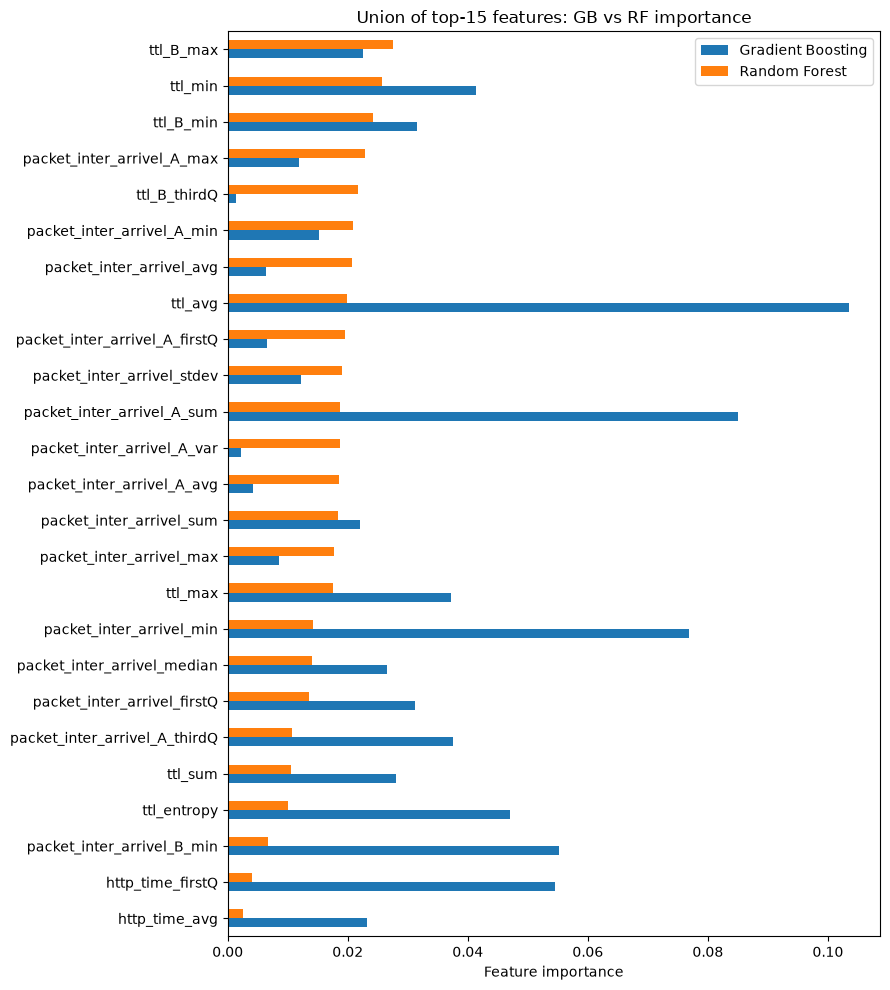

In [38]:
top_union = list((top_gb | top_rf))
plot_df = imp.loc[top_union].sort_values('Random Forest')

plot_df.plot.barh(figsize=(9, 10))
plt.title(f'Union of top-{k} features: GB vs RF importance')
plt.xlabel('Feature importance')
plt.tight_layout()
plt.show()


4. **Analyze feature importance**  
   - Compare the feature importance resulting from each model. Do this both qualitatively and quantitatively (for example, by examining the similarity between feature importance vectors).
   - Are the most important features consistent across models? Which ones are these? Please, keep this discussion concise but thoughtful—focus on patterns and possible explanations rather than just listing numbers.
    
5. **Reflection**:  How do you think the models performed compared to random guessing?  *Hint:* A baseline accuracy of 50% assumes uniform random guessing between two categories. Since this is a multi-class problem, how should that baseline change?

## Part 3: Histogram-Based Gradient Boosting (20 points) - Michelle

Gradient Boosting is a powerful algorithm, but it can also be computationally expensive. To address this limitation, a modern and optimized implementation inspired by *LightGBM* has been introduced (see recommended reading). In `scikit-learn`, this approach is available through `HistGradientBoostingClassifier`.

Here, you will explore how this implementation differs from the traditional `GradientBoostingClassifier`, understand the mechanisms behind its computational efficiency, and apply it to the same dataset used previously.

You should complete the following steps:

1. **Read and summarize**  
   Read the [Histogram-based Gradient Boosting documentation](https://scikit-learn.org/stable/modules/ensemble.html#histogram-based-gradient-boosting), which describes the algorithm and its key differences from `GradientBoostingClassifier`.  

   *Optional (for deeper understanding):*
   - Ke et al. (2017). *[LightGBM: A Highly Efficient Gradient Boosting Decision Tree](https://proceedings.neurips.cc/paper_files/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html)*  
   - *[Introduction to Boosted Trees — XGBoost documentation](https://xgboost.readthedocs.io/en/stable/tutorials/model.html)*  

   Then, briefly answer the following questions:  
   - What are the main differences between `HistGradientBoostingClassifier` and `GradientBoostingClassifier`?  
   - How does histogram binning make training faster?

2. **Optimize and train a `HistGradientBoostingClassifier` object from `sklearn.ensemble`**  
   - Use the same approach you applied to Gradient Boosting in Part 2.  
   - Reuse the same `param_grid` from Part 2.  
   - Use `GridSearchCV` for hyperparameter tuning.  
   - Use the same cross-validation object to ensure a fair comparison.

3. **Evaluate the optimized model**  
   - Report the accuracy and confusion matrix.
   - Measure and report the total hyperparameter search time, following the same procedure used in Part 2.
4. **Reflection**  
   - How does this method compare to `GradientBoostingClassifier` in terms of computation time and predictive performance? Discuss any trade-offs you observe.

**ANSWERS**

1.

- HistGradientBoostingClassifier vs GradientBoostingClassifier: The former can be orders of magnitude faster than the latter when the number of samples is larger than tens of thousands of samples. Also, HGBC has a built-in support system for missing values and categorical features that GBC does not. So GBC cannot process data containing NaN or null values and requires one-hot-encoding.

- The fast estimators first bin the input samples X into integer-valued bins (typically 256 bins) which tremendously reduces the number of splitting points to consider, and allows the algorithm to leverage integer-based data structures (histograms) instead of relying on sorted continuous values when building the trees. Also, HGBT uses an efficient binning algorithm that can handle large datasets with a high number of features. The binning algorithm can pre-process the data to speed up the subsequent tree construction.

## Part 4: Neural Network Model (20 points) - Kavan

In this final part of the assignment, you will revisit neural networks and compare their performance with the ensemble methods explored in the previous parts.

You should do the following:

1. **Preprocessing reflection**  
   - Briefly describe which preprocessing steps are important before training a neural network.  
   - If such steps are necessary in this case, apply them before training your model.

2. **Model optimization and training**  
   - Use NINE different combinations of hidden units and hidden layers as the hyperparameters to tune.
   - Use early stopping to reduce the risk of overfitting.  
   - Train the model for up to 300 epochs.  
   - Use `GridSearchCV` to optimize the model’s hyperparameters.  
   - Make sure to use the same cross-validation object as in Parts 2 and 3 for a fair comparison.  
   - *Tip:* Check the [MLPClassifier documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html) to see how to enable early stopping and adjust other parameters.

3. **Evaluate performance**  
   - Use the same evaluation metrics as in Parts 2 and 3.  
   - Compare the neural network’s performance with the ensemble models.  
   - Reflect on how model complexity and interpretability differ across methods.

**Constraint:**  
Use `MLPClassifier` from `scikit-learn` for this exercise.


1. For a neural-network, the data must be standardized because each layer makes decisions based on comparisons between features with different units. The distance between data points must be relative in order to properly compare results. (RE-WRITE)

In [ ]:
# USE AS MANY CELLS AS NEEDED

## Part 5: Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

YOUR TEXT HERE